# Synthetic 3dBox study with production and AVO data

This notebook runs a complete **synthetic** history-matching study with APEX on the 3dBox case (60×60×5 cells of 30 m, three water injectors and three producers, OPM Flow):

1. check the case: the true model's data (the wells' oil and water rates and water injection rates (1,197 data) and RMS maps of the 10° and 20° AVO angle stacks at two vintages (4 × 3,600 values), wavelet-compressed to 1,394 coefficients) written by `prepare.py`, and the four configurations;
2. history-match the **log-permeability and the porosity** of every cell (36,000 unknowns, 100 members) with ES-MDA (4 steps, α = 4) and GIES/RLM-MAC (at most 10 iterations), each with and without adaptive localization (`adaptive_prior` with the fixed threshold 3/√N = 0.3);
3. tabulate the prior and final metrics: normalized data mismatch, RMSE and SSIM of both variables against the true model, and the spread kept; and the same at every kept iteration of each experiment;
4. plot the results.

Run it from `examples/3dbox_production_avo/` with OPM Flow on `PATH`. The four runs take a few hours on 10 cores; existing results in `results/` are reused.

In [1]:
import sys
from pathlib import Path

from IPython.display import Image, Markdown, display

HERE = Path.cwd()  # run from examples/3dbox_production_avo/
sys.path.insert(0, str(HERE))
import synthetic_demo as demo  # noqa: E402

FONT_SIZE = 12  # of every figure

## 1. The case

`prepare.py` ran the true model once and wrote the observations: each rate with a standard deviation of 10 % of its value, at least 8 sm³/day, and each AVO map with 5 % of its mean |value|. Each configuration's plan, as `apex validate` gives it (nothing is simulated):

In [2]:
for name, (label, _) in demo.EXPERIMENTS.items():
    print(f"{label:26} {demo.plan(name)}")
print()
print((HERE / "config_gies.toml").read_text())

ES-MDA                     esmda, 100 members, 36000 unknowns, 2591 data; at most 5 forecasts, 500 simulations


GIES                       gies, 100 members, 36000 unknowns, 2591 data; at most 11 forecasts, 1121 simulations


ES-MDA, no localization    esmda, 100 members, 36000 unknowns, 2591 data; at most 5 forecasts, 500 simulations


GIES, no localization      gies, 100 members, 36000 unknowns, 2591 data; at most 11 forecasts, 1121 simulations

# The 3dBox AVO case, written by prepare.py: GIES (RLM-MAC, 10 iterations) on the wells' rates
# and RMS maps of two angle stacks at two vintages, on OPM Flow; the log-permeability and
# the porosity are uncertain (AVO data are sensitive to porosity).
[run]
name = "3dbox_production_avo_gies"
seed = 2026

[[state.variables]]
name = "permx"   # ln PERMX (mD); the deck caps it at permx_cap
size = 18000
grid = [60, 60, 5]
lower = -3.0     # bounds just outside the truth's -2.2 ... 6.9: members are clipped to them
upper = 10.0

[[state.variables]]
name = "poro"
size = 18000
grid = [60, 60, 5]
lower = 0.01
upper = 0.4

[prior]   # 100 members drawn by prepare.py: ln PERMX and a porosity correlated with it (0.7)
generator = { name = "file", options = { ensemble_file = "prior_ensemble.npz" } }

[observations]
file = "observations.csv"

[[observations.fields]]
time = "2027-06-24"
dat

## 2. History matching

Each experiment writes its run directory to `results/<experiment>/`: per step the ensemble and its forecast (`checkpoints/iter_<k>.npz`), the per-member data mismatch and metrics (`data_mismatch_<k>.npz`), the history and a summary. Existing results are kept (pass `rerun=True` to recompute them).

In [3]:
runs = demo.run_experiments()
results = demo.load_results(runs)
for name, run in results.items():
    label = demo.EXPERIMENTS[name][0]
    print(f"{label:26} forecasts: {len(run.history):2}  kept: {run.accepted_iterations}")

ES-MDA                     forecasts:  5  kept: [0, 1, 2, 3, 4]
GIES                       forecasts:  9  kept: [0, 1, 2, 3, 4, 5, 6, 7, 8]
ES-MDA, no localization    forecasts:  5  kept: [0, 1, 2, 3, 4]
GIES, no localization      forecasts: 11  kept: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


## 3. Final metrics

Member means at the prior and the final iterate (the mismatch is the normalized data mismatch). **Spread** is the posterior standard deviation over the prior's, averaged over the cells.

In [4]:
demo.write_table(results)  # results/comparison/final_metrics.csv
rows = [demo.summary_row(name, run) for name, run in results.items()]
columns = {"mismatch all": "normalized_data_mismatch_all"}
columns |= {f"mismatch {t}": f"normalized_data_mismatch_{t}" for t in demo.FIELD_TYPES}
for variable in demo.VARIABLES:
    columns[f"RMSE {variable}"] = f"rmse_{variable}"
    columns[f"SSIM {variable}"] = f"ssim_{variable}"
spreads = {f"spread {v}": f"spread_{v}" for v in demo.VARIABLES}


summary = [
    {"": "prior"}
    | {c: rows[0][k + "_prior"] for c, k in columns.items()}
    | dict.fromkeys(spreads, 1.0)
]
for row in rows:
    summary.append(
        {"": row["experiment"]}
        | {c: row[k + "_final"] for c, k in columns.items()}
        | {c: row[k] for c, k in spreads.items()}
    )
display(Markdown(demo.markdown_table(summary)))

|  | mismatch all | mismatch avo_10 | mismatch avo_20 | RMSE permx | SSIM permx | RMSE poro | SSIM poro | spread permx | spread poro |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| prior | 2.285e+05 | 2637 | 3610 | 1.345 | 0.3219 | 0.08235 | 0.1531 | 1 | 1 |
| ES-MDA | 5.95e+04 | 1534 | 2566 | 1.45 | 0.2851 | 0.07935 | 0.1972 | 0.9685 | 0.8871 |
| GIES | 7.918e+04 | 2233 | 3117 | 1.323 | 0.3311 | 0.08054 | 0.1722 | 0.9879 | 0.9843 |
| ES-MDA, no localization | 8.962e+05 | 2.306e+04 | 4.583e+04 | 4.771 | 0.02202 | 0.1792 | 0.0304 | 0.004901 | 0.00244 |
| GIES, no localization | 1.153e+04 | 1849 | 3034 | 1.756 | 0.2657 | 0.08767 | 0.145 | 0.3864 | 0.3674 |

### 3.1 Metrics at each iteration

The same member means at every kept iteration of each experiment (iteration 0 is the prior; GIES keeps only its accepted iterations), with the spread kept at that iteration. The mismatch of each AVO map is over its kept wavelet coefficients. The tables are also written to `results/comparison/metrics_by_iteration_<experiment>.csv`.

In [5]:
tables = demo.write_iteration_tables(results)
for name, rows in tables.items():
    table = demo.markdown_table(rows)
    display(Markdown(f"**{demo.EXPERIMENTS[name][0]}**\n\n{table}"))

**ES-MDA**

| iteration | mismatch all | mismatch avo_10 | mismatch avo_20 | RMSE permx | SSIM permx | RMSE poro | SSIM poro | spread permx | spread poro |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 2.285e+05 | 2637 | 3610 | 1.345 | 0.3219 | 0.08235 | 0.1531 | 1 | 1 |
| 1 | 1.766e+05 | 1658 | 2878 | 1.403 | 0.3086 | 0.08318 | 0.2027 | 0.9766 | 0.9245 |
| 2 | 9.127e+04 | 1537 | 2455 | 1.456 | 0.292 | 0.0799 | 0.1897 | 0.9739 | 0.9013 |
| 3 | 8.349e+04 | 1542 | 2548 | 1.477 | 0.2875 | 0.07973 | 0.1989 | 0.9708 | 0.8926 |
| 4 | 5.95e+04 | 1534 | 2566 | 1.45 | 0.2851 | 0.07935 | 0.1972 | 0.9685 | 0.8871 |

**GIES**

| iteration | mismatch all | mismatch avo_10 | mismatch avo_20 | RMSE permx | SSIM permx | RMSE poro | SSIM poro | spread permx | spread poro |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 2.285e+05 | 2637 | 3610 | 1.345 | 0.3219 | 0.08235 | 0.1531 | 1 | 1 |
| 1 | 9.691e+04 | 2593 | 3570 | 1.328 | 0.33 | 0.08189 | 0.1588 | 0.9959 | 0.9982 |
| 2 | 9.065e+04 | 2547 | 3514 | 1.33 | 0.3296 | 0.08165 | 0.1615 | 0.9942 | 0.9964 |
| 3 | 8.453e+04 | 2496 | 3450 | 1.33 | 0.3296 | 0.08143 | 0.1635 | 0.993 | 0.9946 |
| 4 | 8.26e+04 | 2444 | 3383 | 1.329 | 0.3297 | 0.08124 | 0.1653 | 0.992 | 0.9927 |
| 5 | 8.093e+04 | 2390 | 3315 | 1.328 | 0.3299 | 0.08106 | 0.167 | 0.991 | 0.9906 |
| 6 | 8.011e+04 | 2337 | 3248 | 1.326 | 0.3303 | 0.08088 | 0.1687 | 0.9899 | 0.9885 |
| 7 | 7.948e+04 | 2285 | 3182 | 1.325 | 0.3307 | 0.08071 | 0.1704 | 0.9889 | 0.9864 |
| 8 | 7.918e+04 | 2233 | 3117 | 1.323 | 0.3311 | 0.08054 | 0.1722 | 0.9879 | 0.9843 |

**ES-MDA, no localization**

| iteration | mismatch all | mismatch avo_10 | mismatch avo_20 | RMSE permx | SSIM permx | RMSE poro | SSIM poro | spread permx | spread poro |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 2.285e+05 | 2637 | 3610 | 1.345 | 0.3219 | 0.08235 | 0.1531 | 1 | 1 |
| 1 | 1.614e+06 | 1.258e+04 | 2.385e+04 | 2.784 | 0.1324 | 0.1307 | 0.1553 | 0.4365 | 0.3709 |
| 2 | 3.514e+06 | 1.538e+04 | 3.121e+04 | 4.573 | 0.04314 | 0.1617 | 0.05627 | 0.02974 | 0.0219 |
| 3 | 2.712e+06 | 2.085e+04 | 4.238e+04 | 4.639 | 0.03119 | 0.1753 | 0.04009 | 0.008299 | 0.004714 |
| 4 | 8.962e+05 | 2.306e+04 | 4.583e+04 | 4.771 | 0.02202 | 0.1792 | 0.0304 | 0.004901 | 0.00244 |

**GIES, no localization**

| iteration | mismatch all | mismatch avo_10 | mismatch avo_20 | RMSE permx | SSIM permx | RMSE poro | SSIM poro | spread permx | spread poro |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 2.285e+05 | 2637 | 3610 | 1.345 | 0.3219 | 0.08235 | 0.1531 | 1 | 1 |
| 1 | 1.174e+05 | 2669 | 3653 | 1.34 | 0.3296 | 0.0825 | 0.1564 | 0.9704 | 0.9749 |
| 2 | 9.047e+04 | 2687 | 3701 | 1.346 | 0.3375 | 0.08256 | 0.1677 | 0.9467 | 0.953 |
| 3 | 8.198e+04 | 2720 | 3802 | 1.362 | 0.341 | 0.08283 | 0.1757 | 0.9243 | 0.9318 |
| 4 | 7.238e+04 | 2752 | 3931 | 1.414 | 0.3354 | 0.08466 | 0.1743 | 0.8987 | 0.9065 |
| 5 | 5.376e+04 | 2699 | 3930 | 1.489 | 0.3236 | 0.0869 | 0.1679 | 0.8663 | 0.8742 |
| 6 | 3.661e+04 | 2719 | 4093 | 1.577 | 0.3012 | 0.08983 | 0.1631 | 0.8176 | 0.8236 |
| 7 | 2.823e+04 | 2613 | 4068 | 1.655 | 0.2711 | 0.09223 | 0.1586 | 0.7409 | 0.7406 |
| 8 | 2.023e+04 | 2407 | 3920 | 1.702 | 0.2742 | 0.09132 | 0.1638 | 0.625 | 0.6159 |
| 9 | 1.782e+04 | 2065 | 3521 | 1.71 | 0.266 | 0.09039 | 0.1515 | 0.511 | 0.4966 |
| 10 | 1.153e+04 | 1849 | 3034 | 1.756 | 0.2657 | 0.08767 | 0.145 | 0.3864 | 0.3674 |

## 4. Figures

### 4.1 Metrics over the iterations

The member mean of each metric for the four experiments:

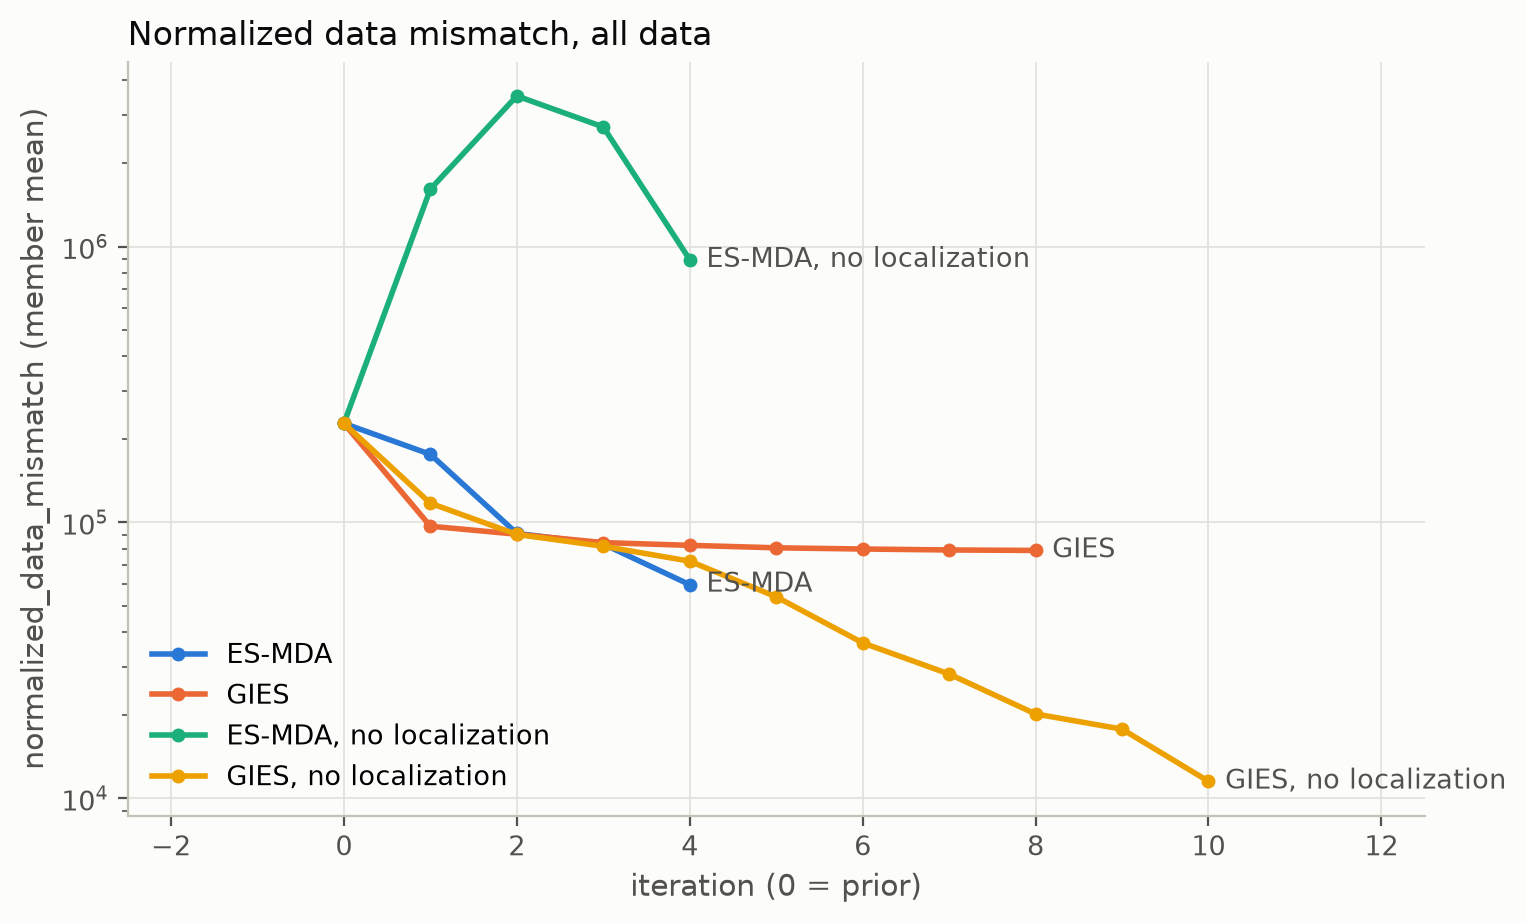

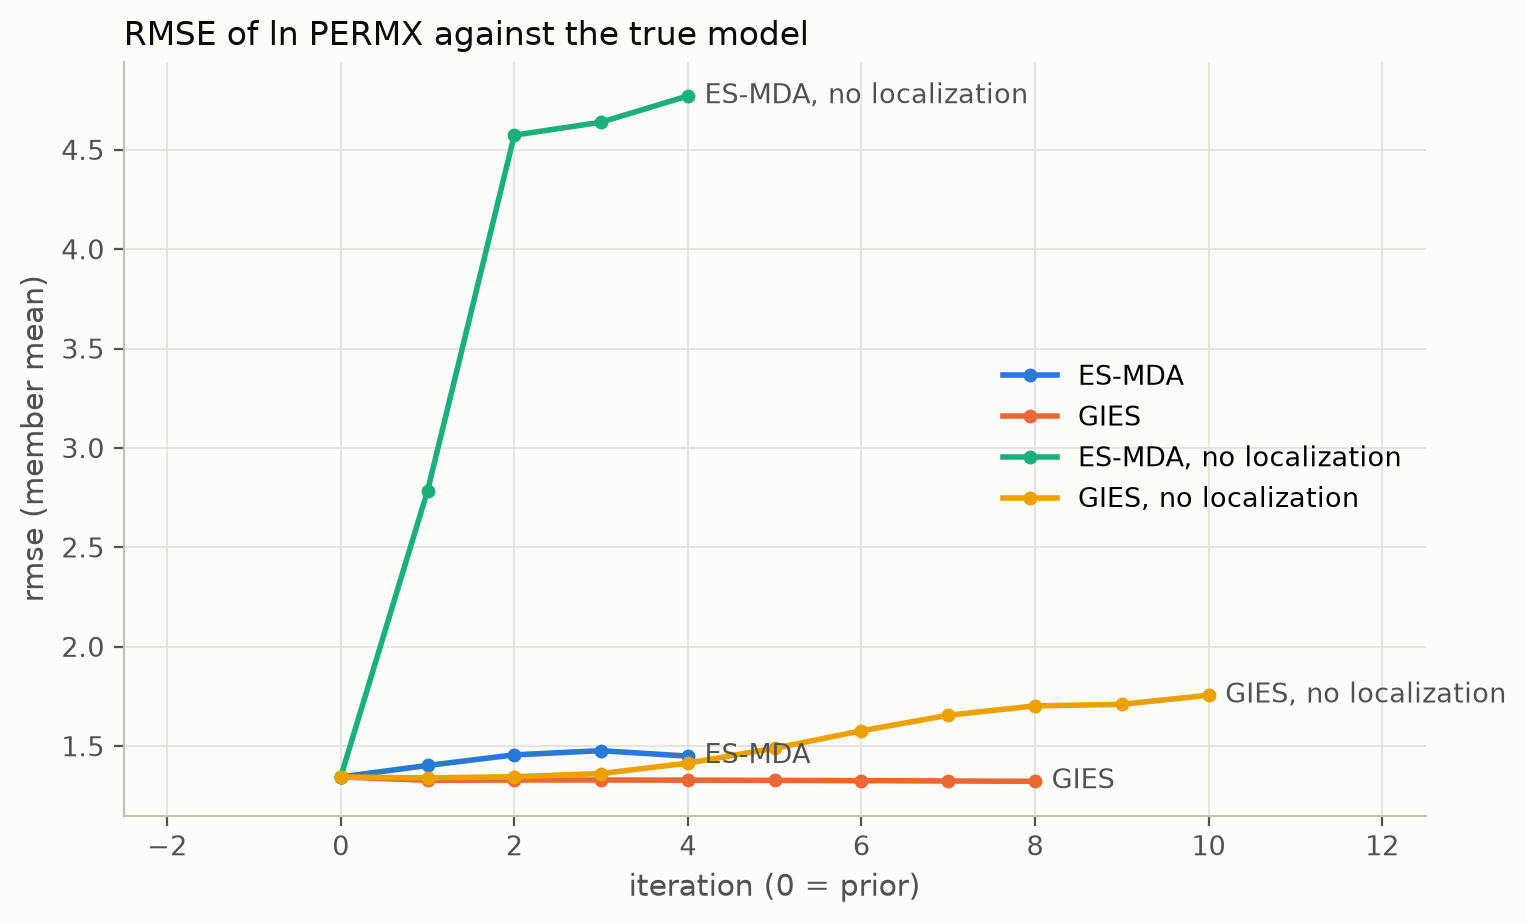

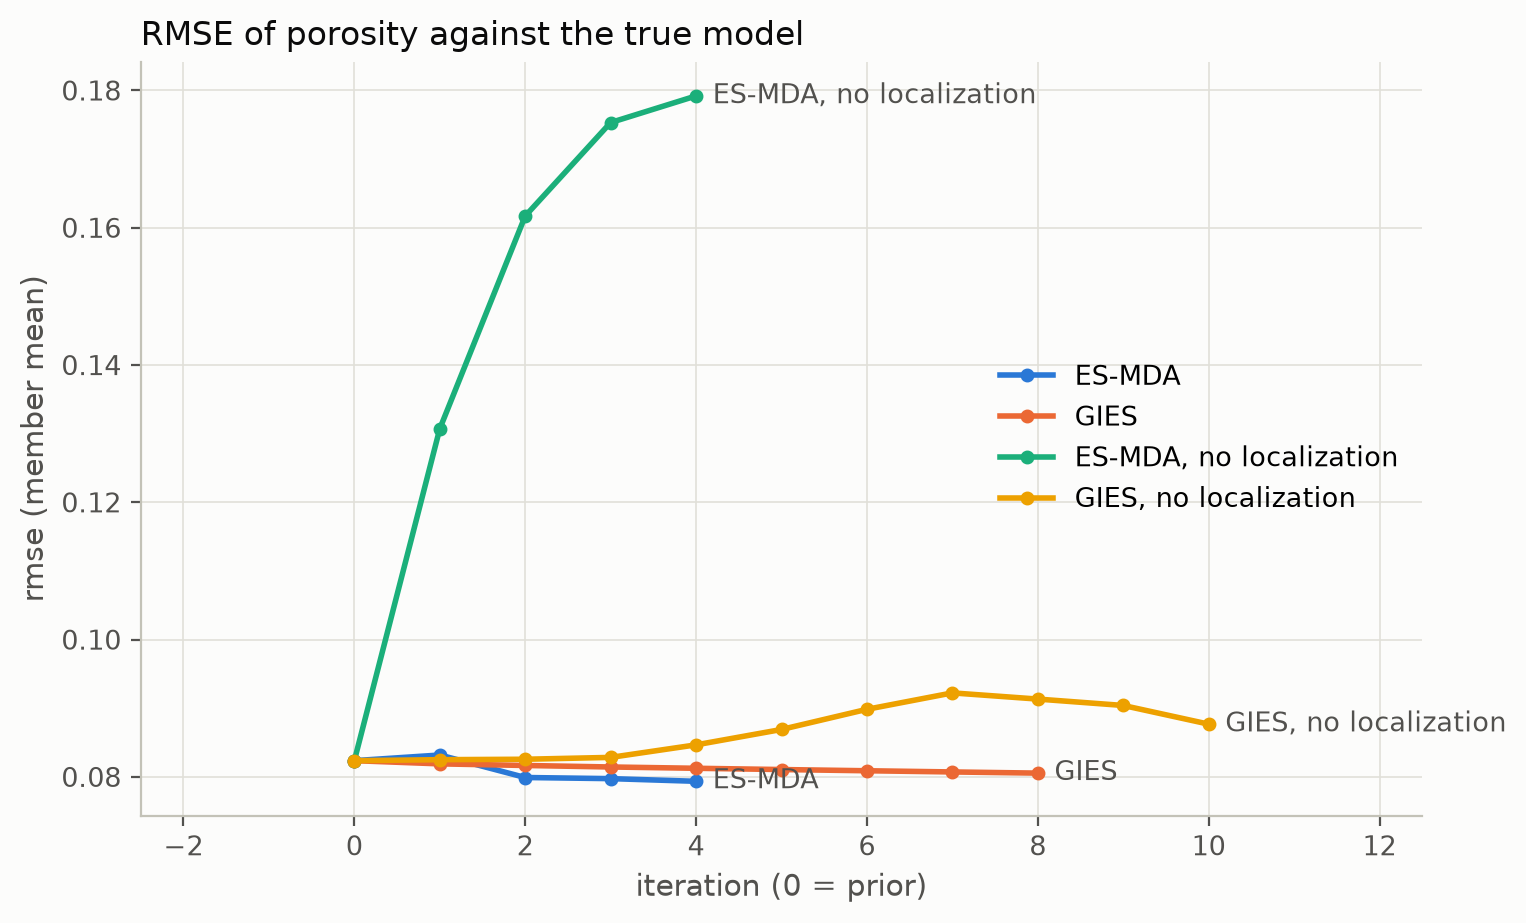

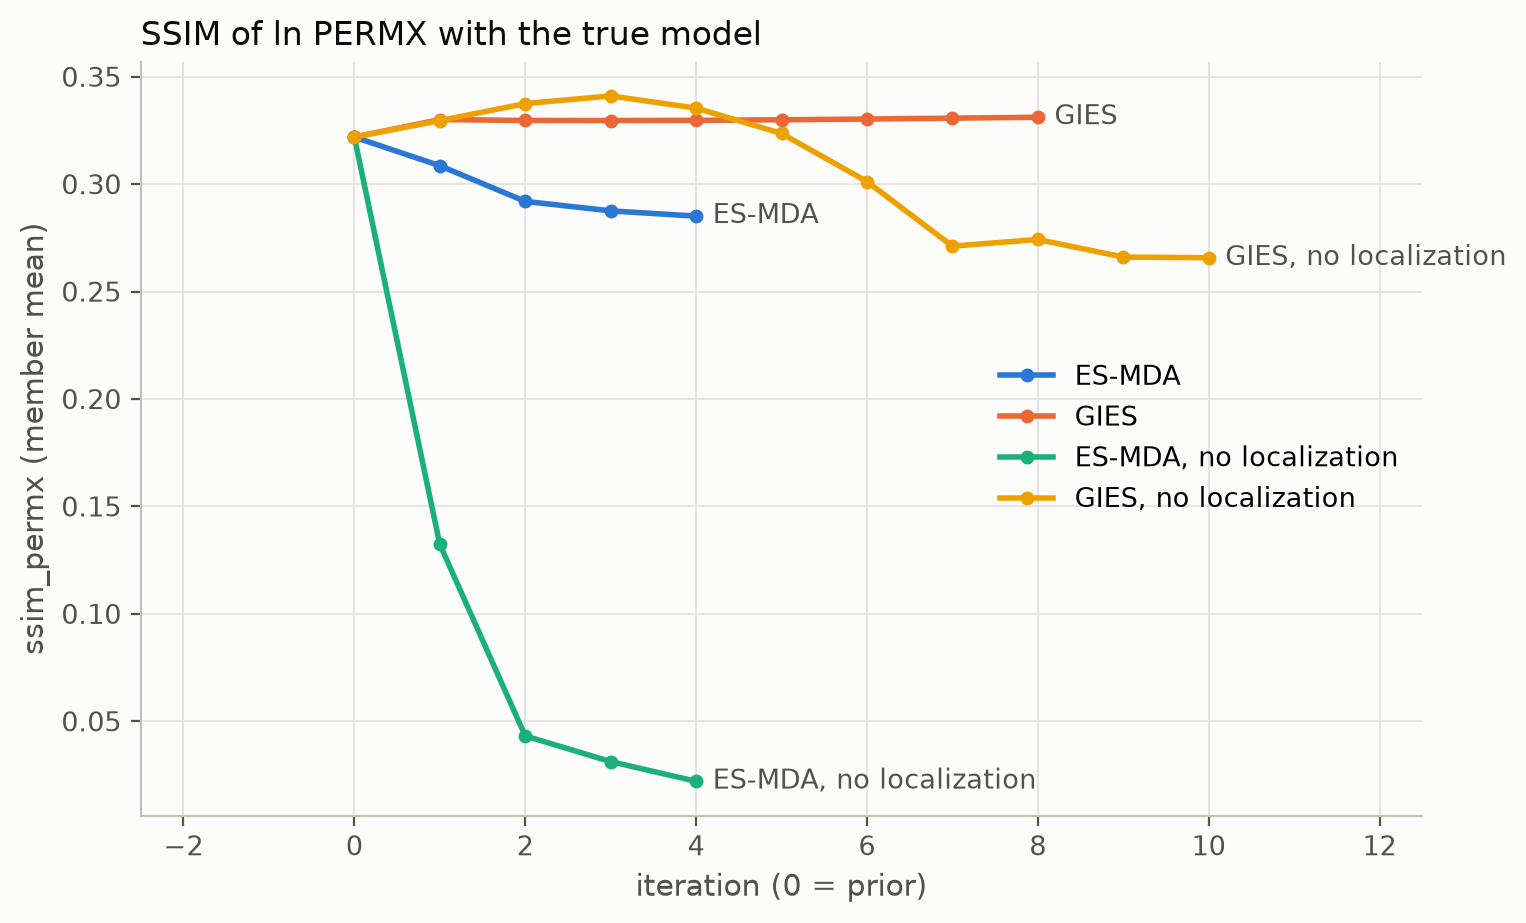

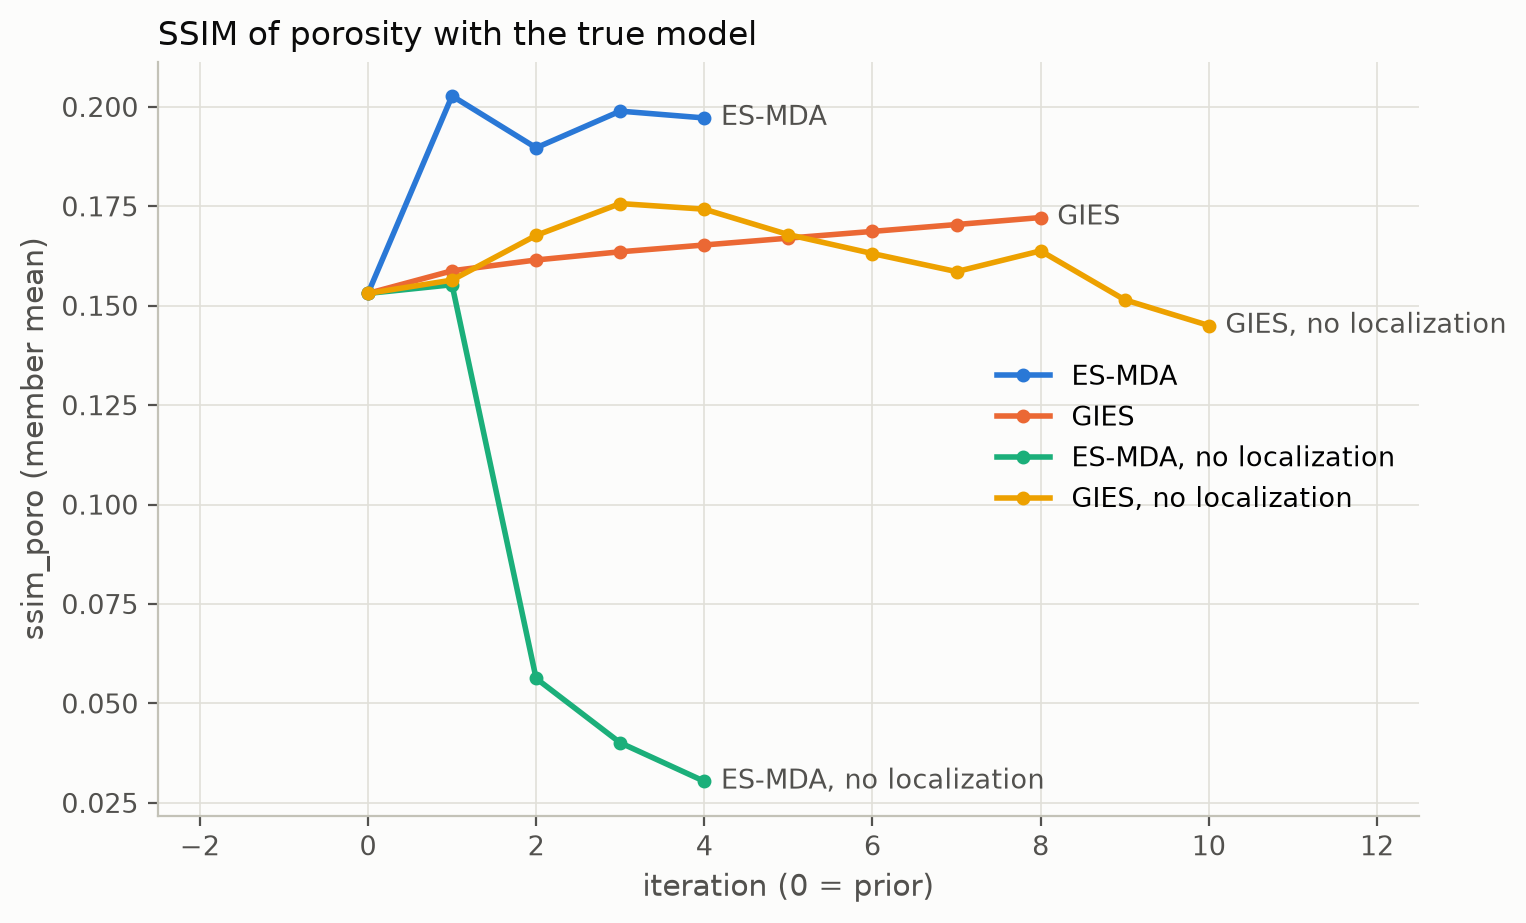

In [6]:
comparison = demo.plot_comparison(results, font_size=FONT_SIZE)
for figure in comparison:
    display(Image(filename=figure.with_suffix(".png"), width=620))

### 4.2 Production data

Per well and data type, the prior and final ensemble forecasts (GIES with localization) against the observations, with the true model's rates:

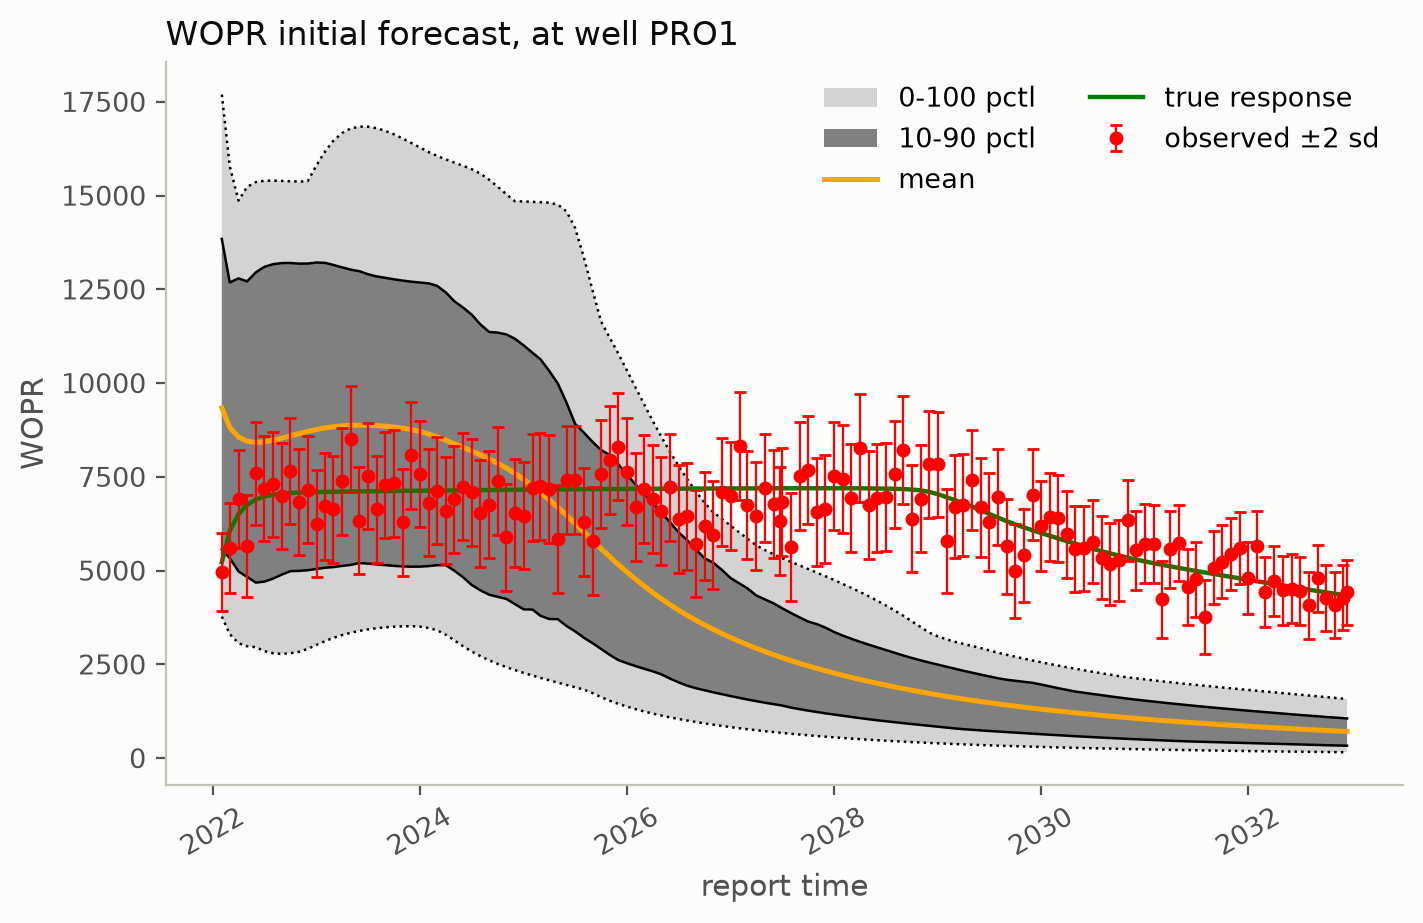

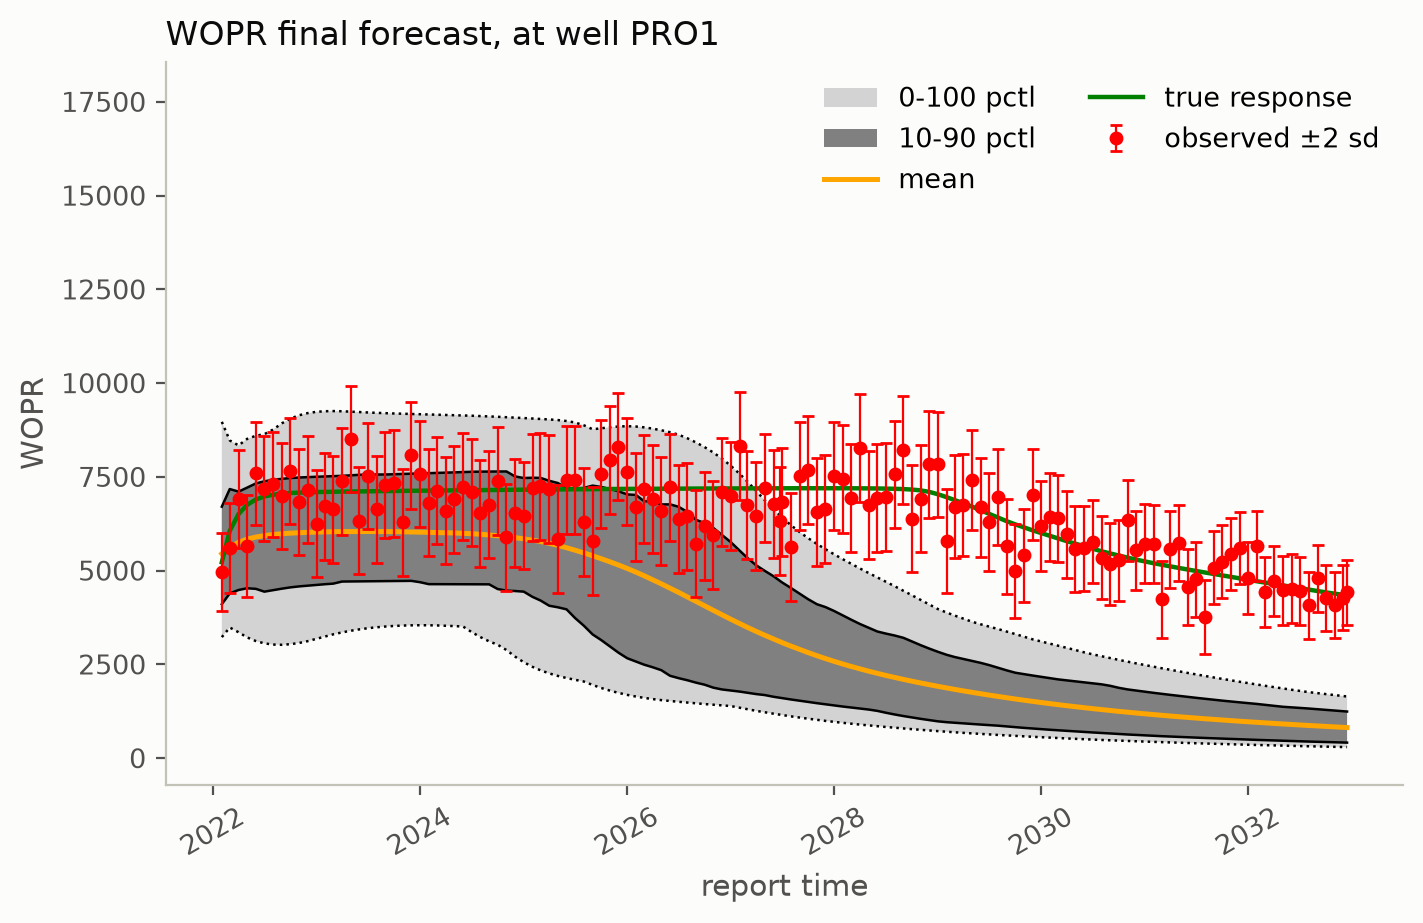

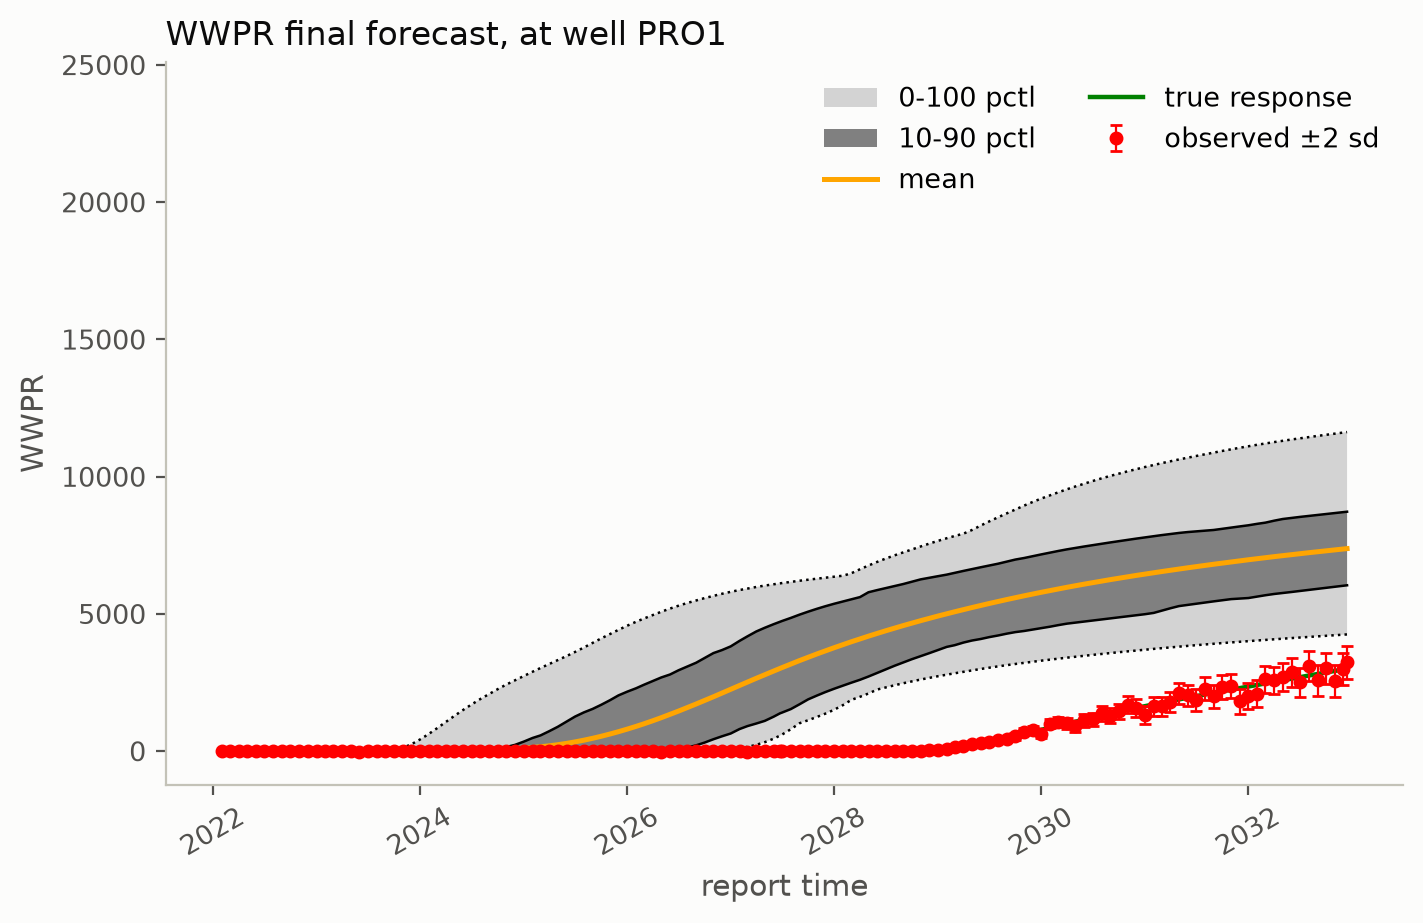

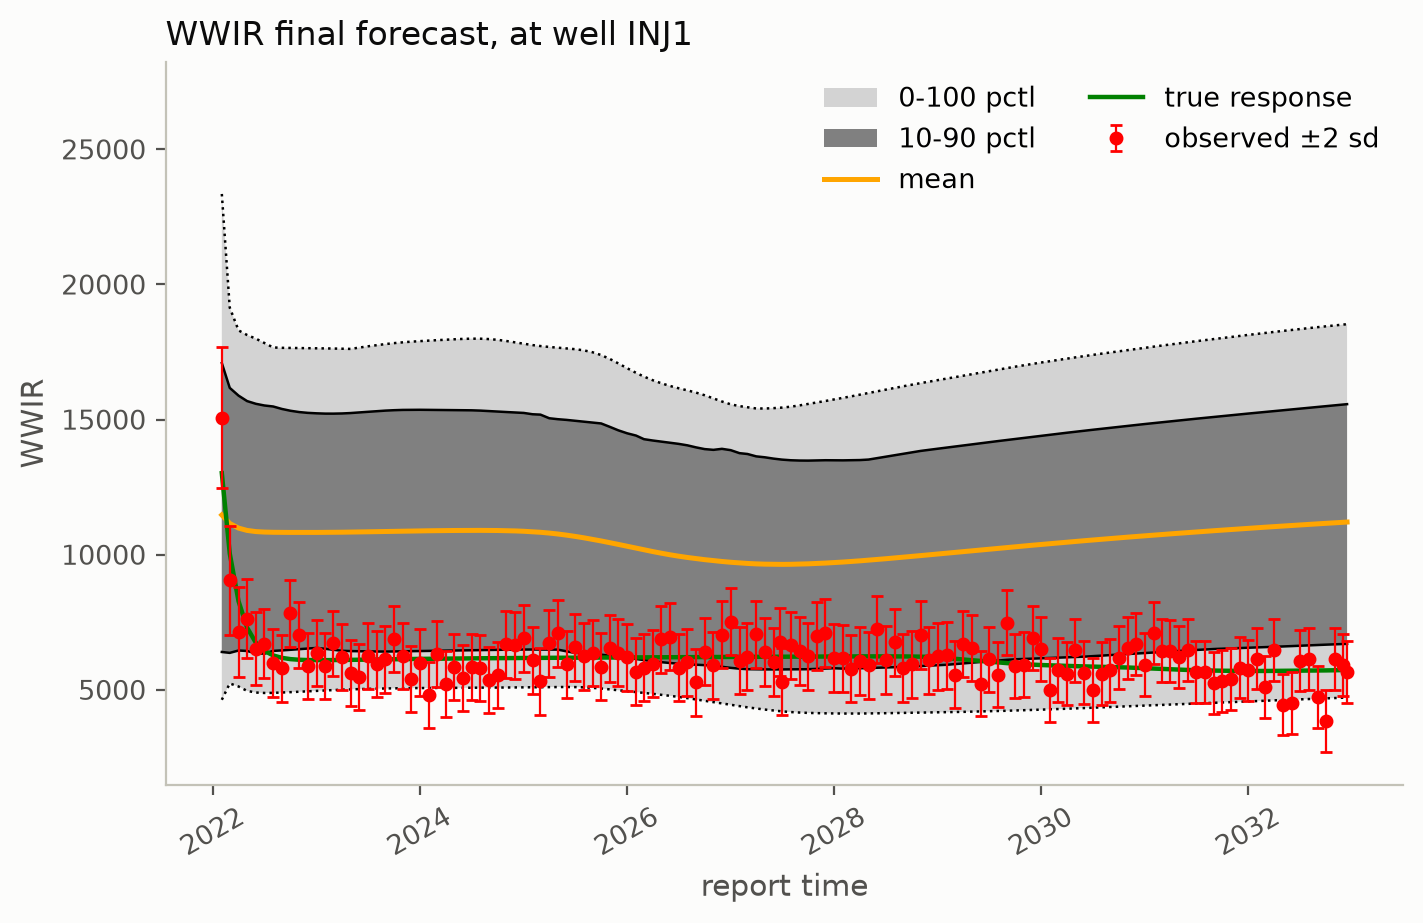

In [7]:
truth = demo.true_response()
reports = {
    name: demo.plot_experiment(path, truth, font_size=FONT_SIZE) for name, path in runs.items()
}
data = runs["gies"] / "report" / "data"
for stem in ("PRO1_WOPR_initial", "PRO1_WOPR_final", "PRO1_WWPR_final", "INJ1_WWIR_final"):
    display(Image(filename=data / f"{stem}.png", width=560))

### 4.3 Parameter fields

Layer 3: the true model, and the final ensemble mean of each experiment, for ln PERMX and porosity (`results/<experiment>/report/fields` has every layer, the means and spreads at the prior and the end, and their differences):

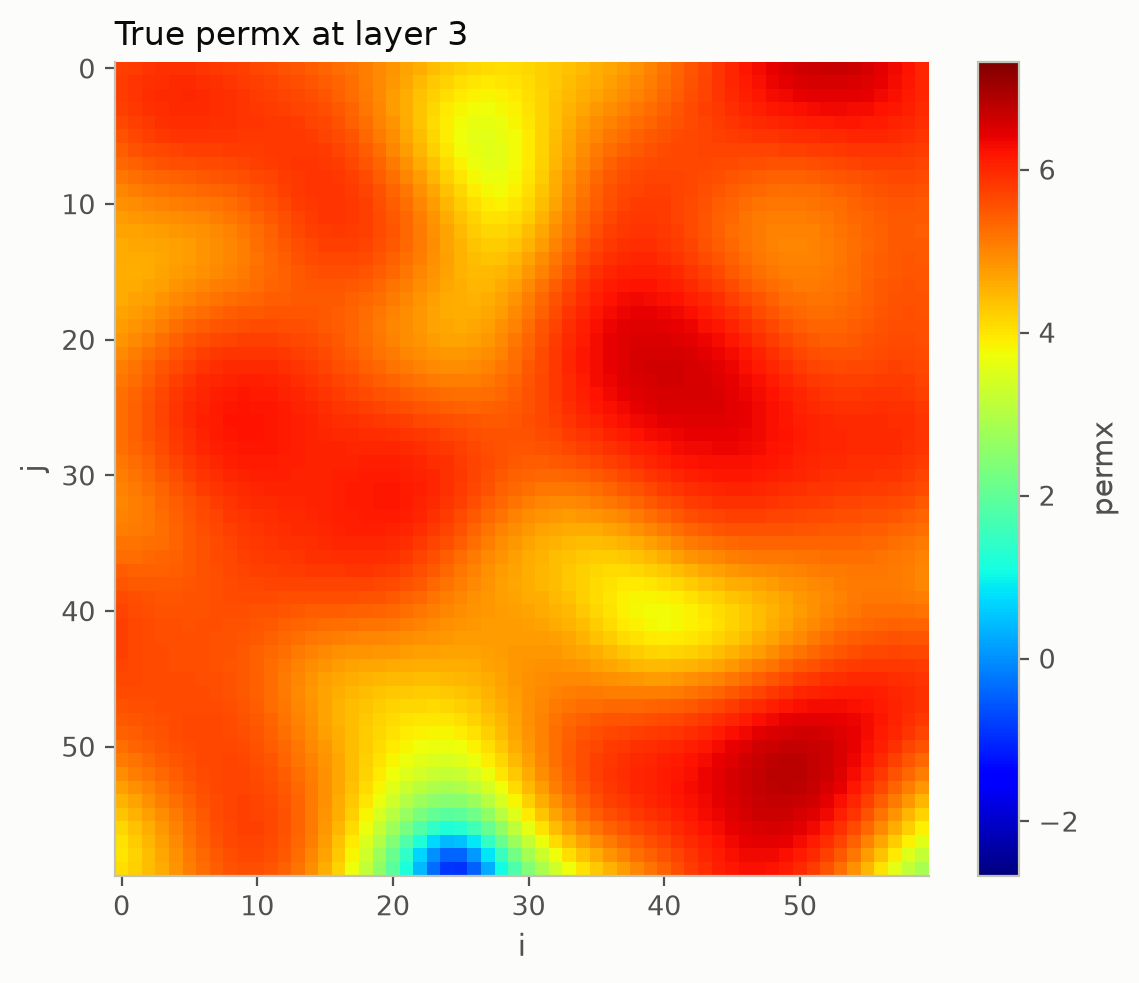

ES-MDA


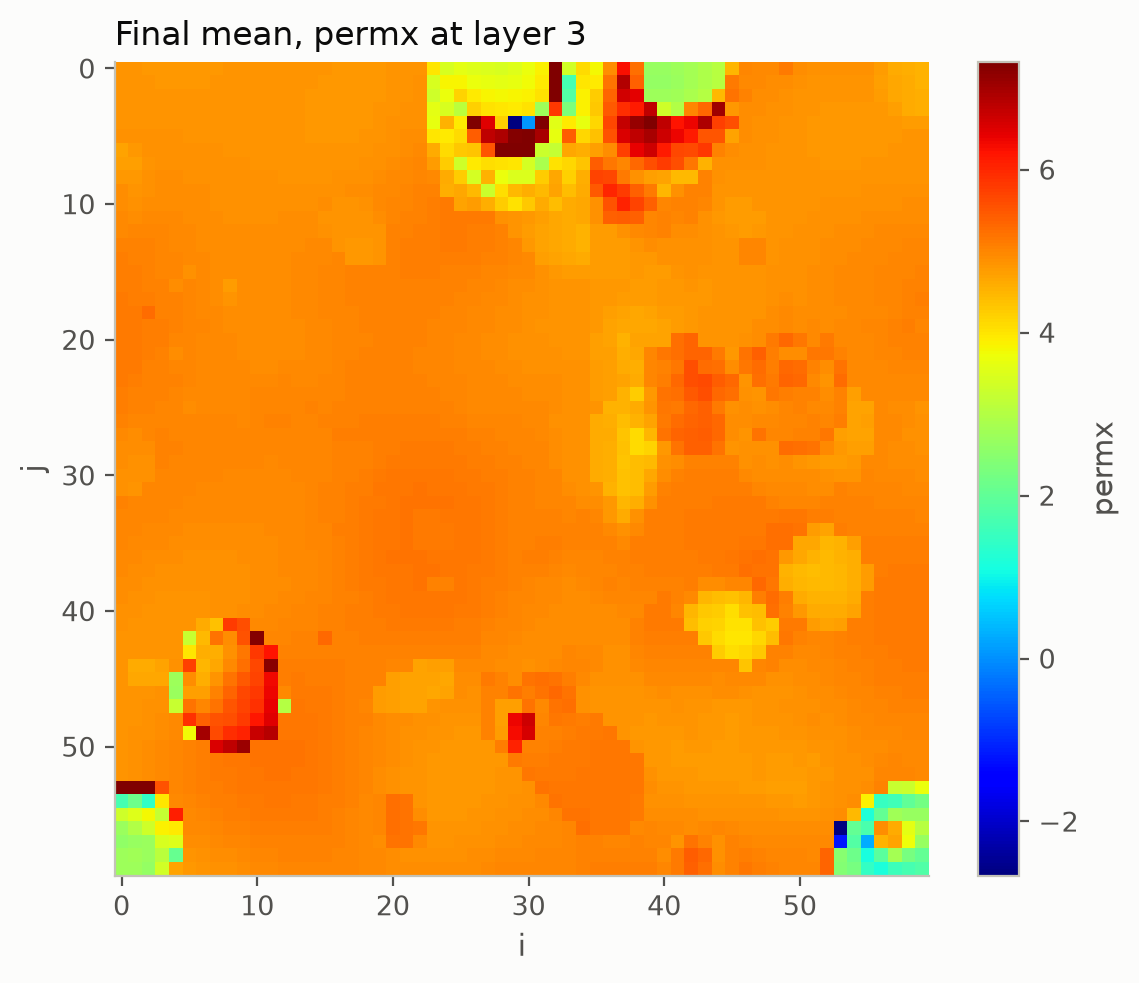

GIES


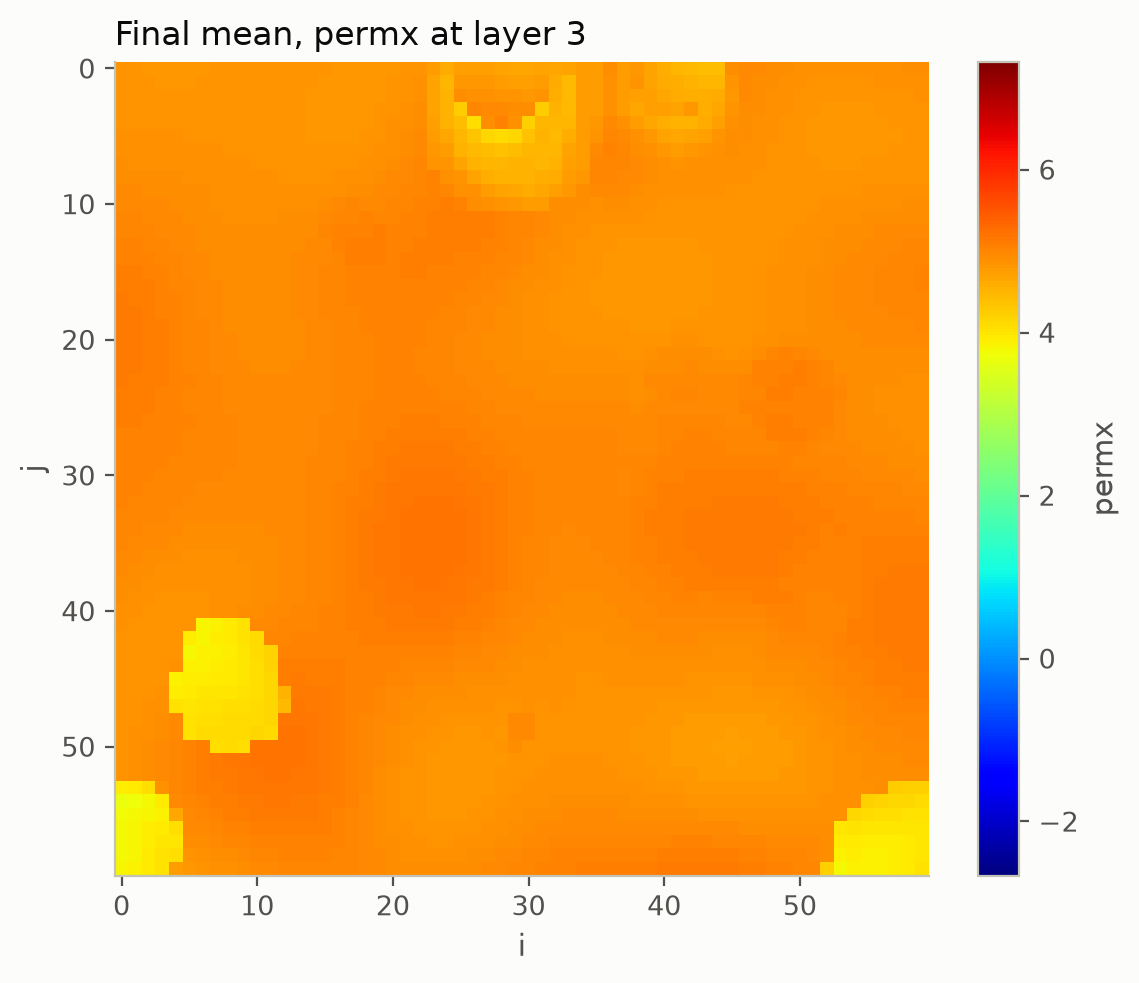

ES-MDA, no localization


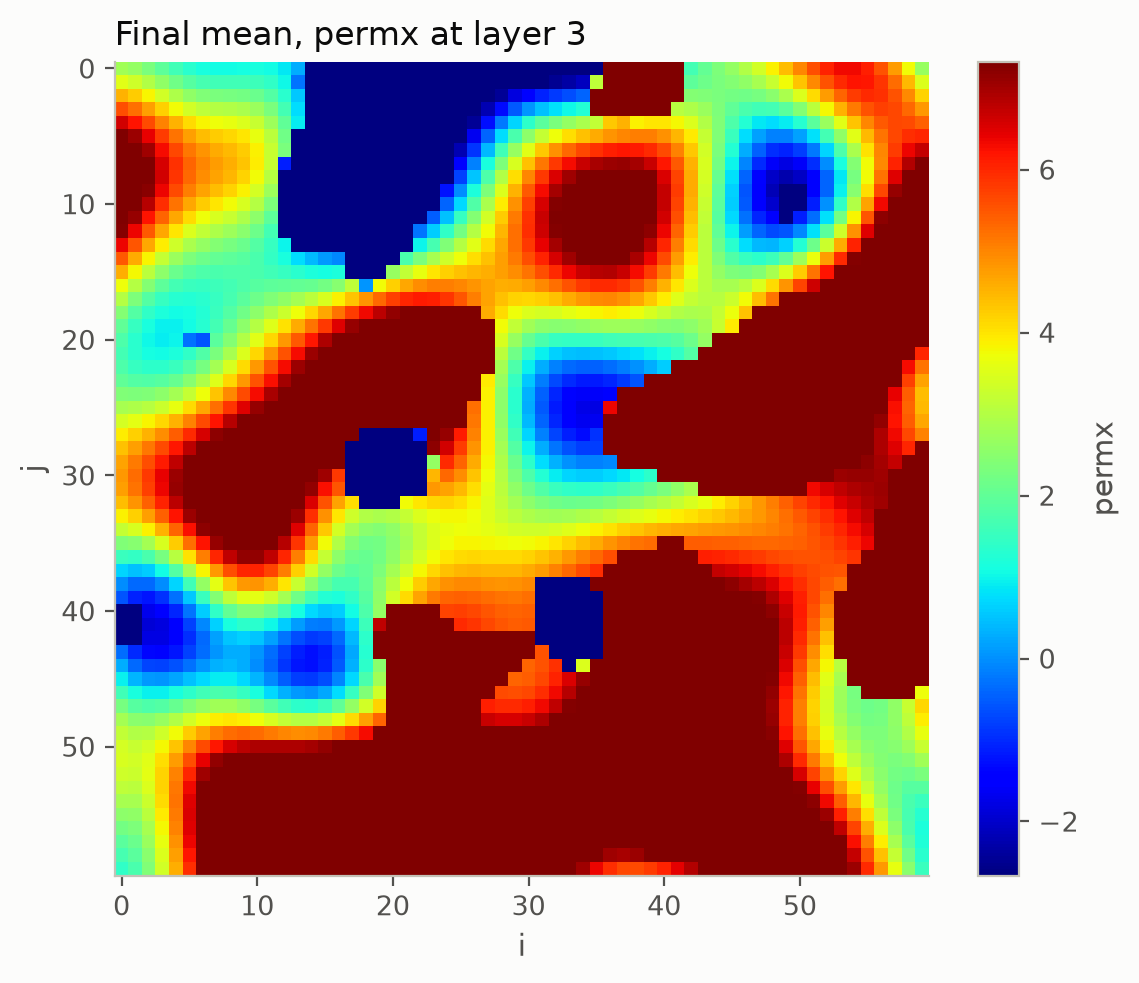

GIES, no localization


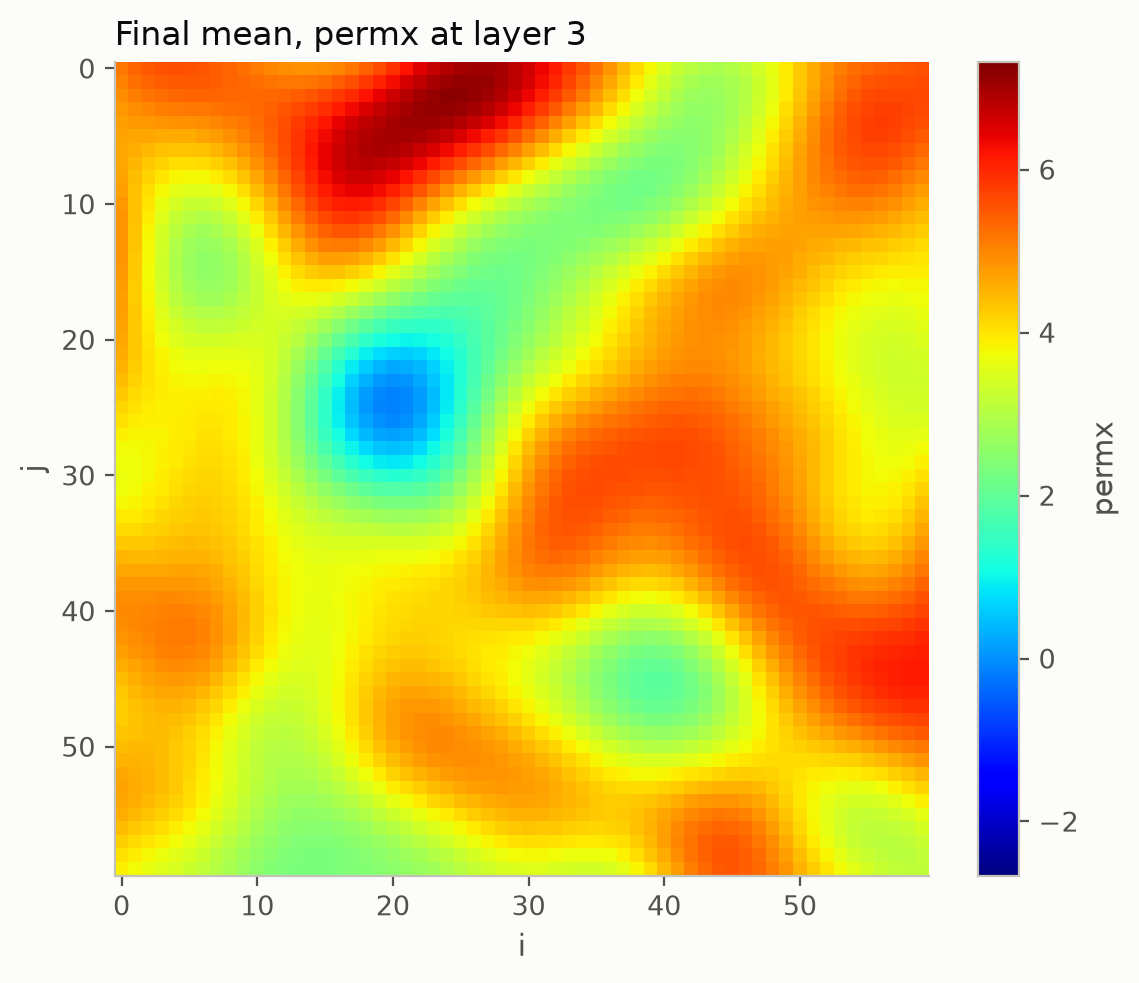

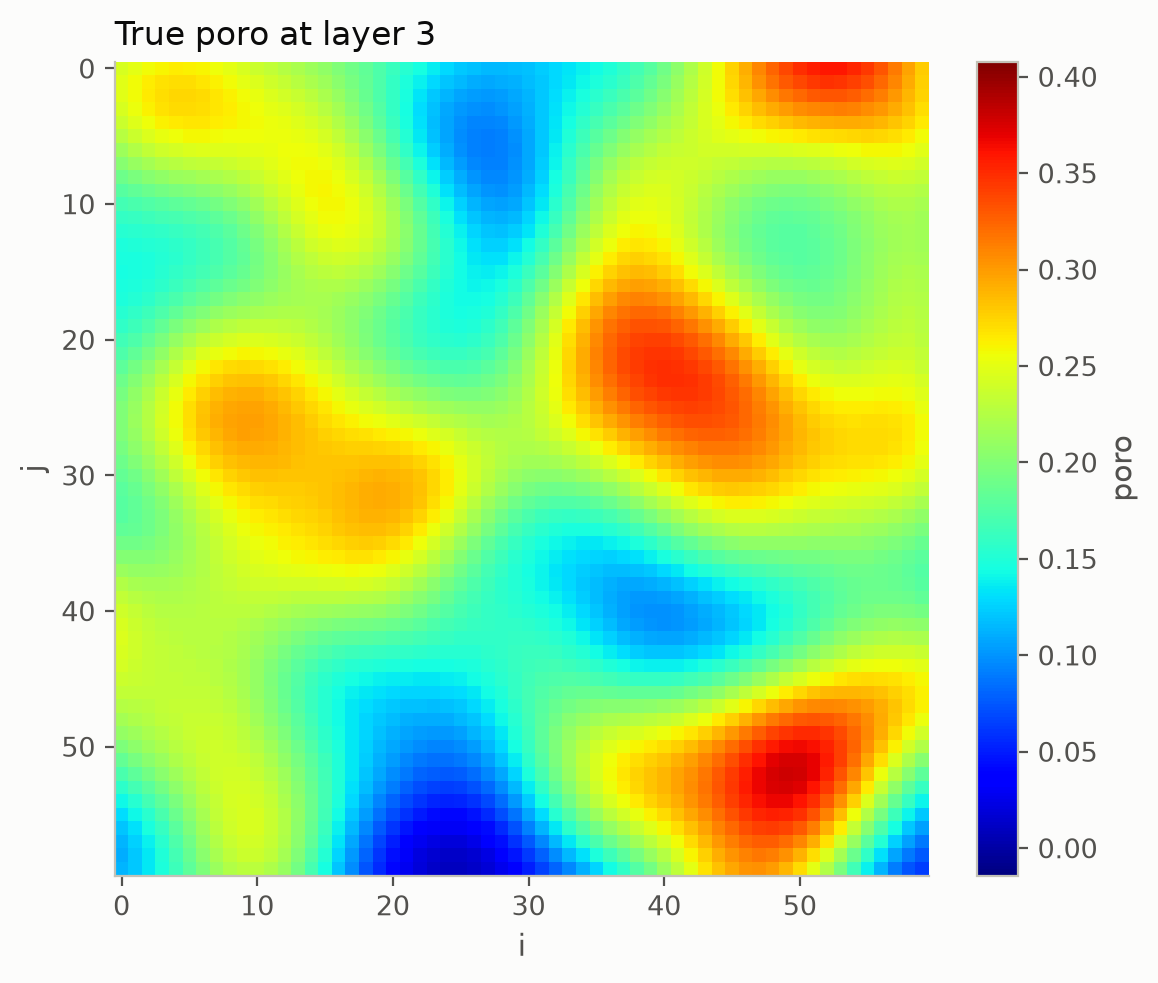

ES-MDA


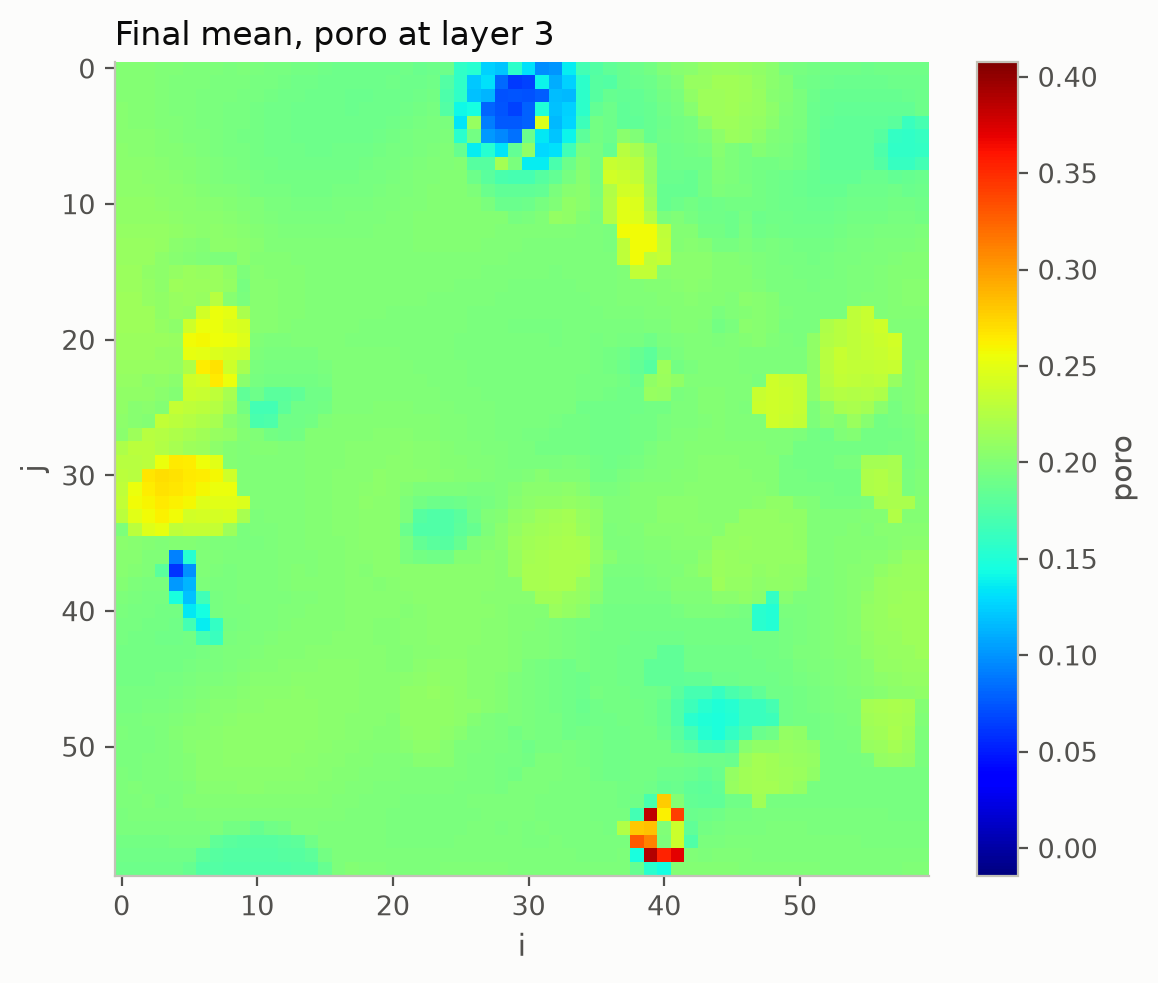

GIES


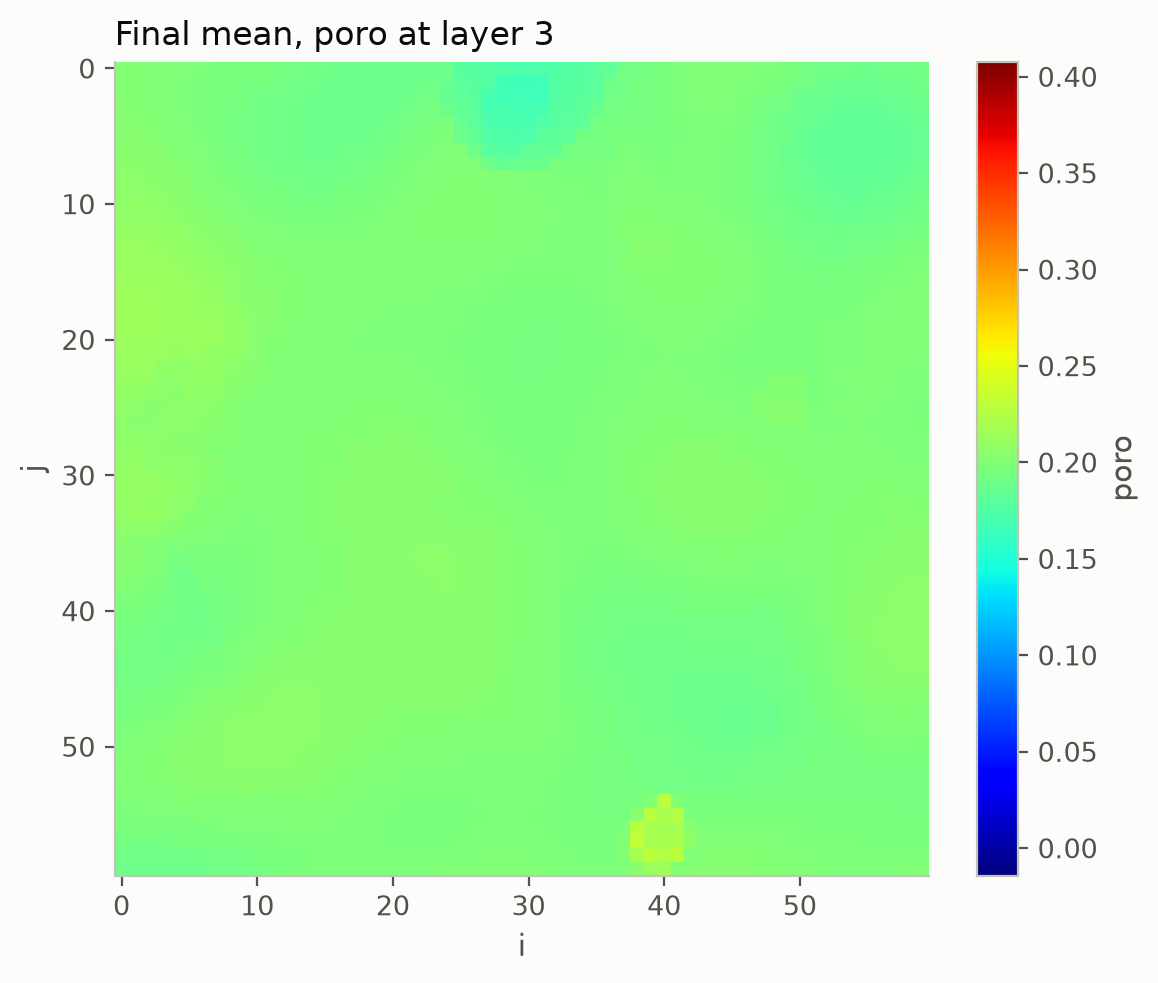

ES-MDA, no localization


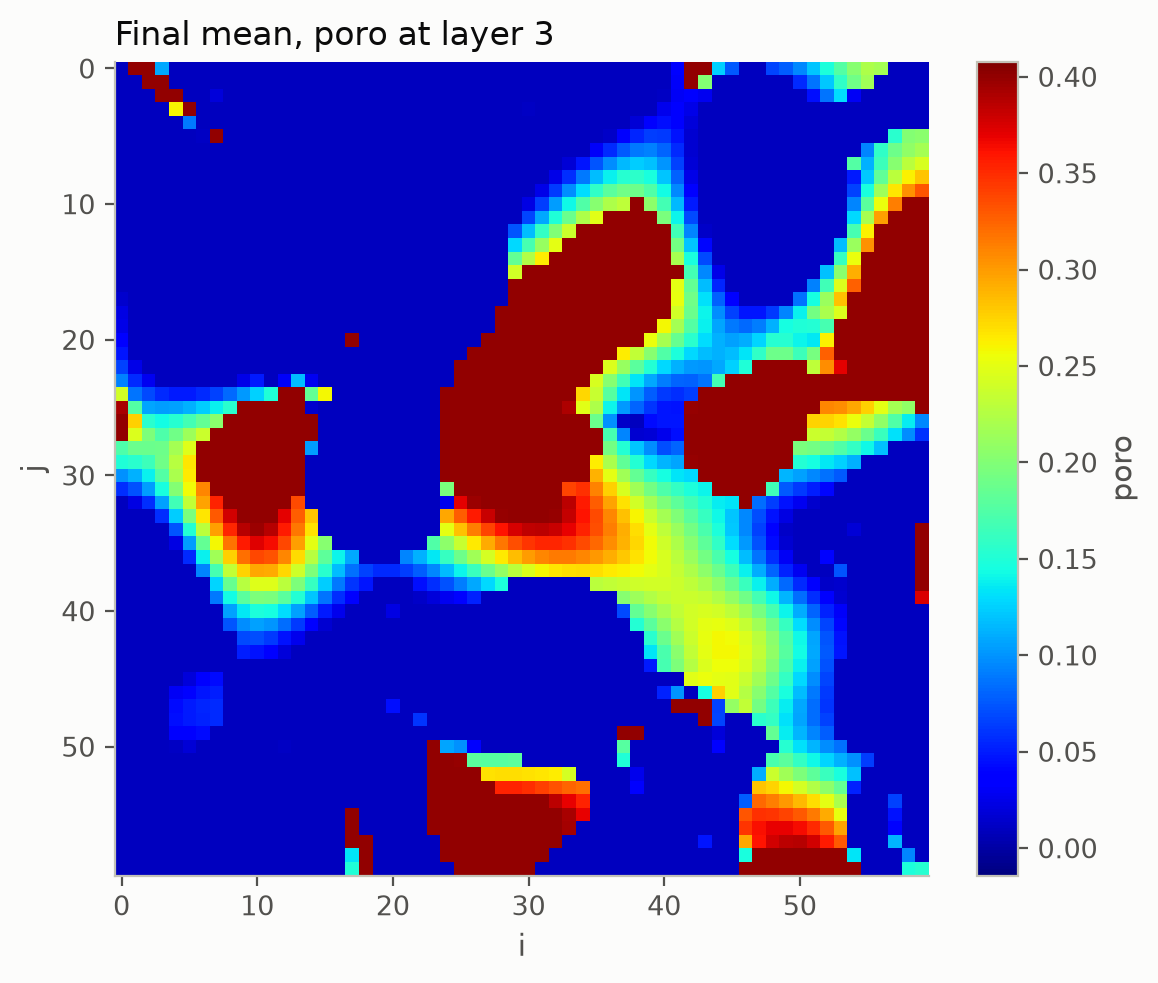

GIES, no localization


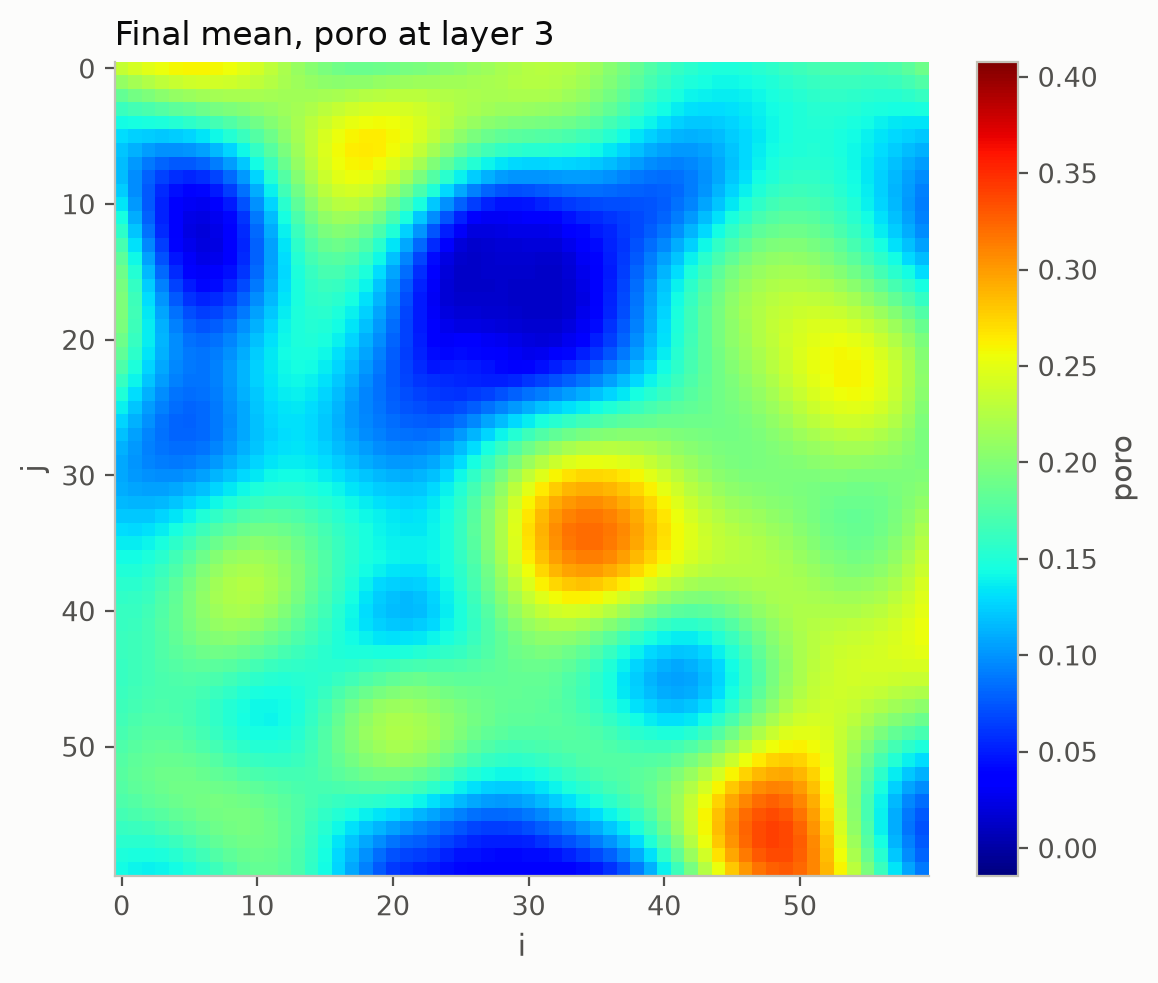

In [8]:
fields = runs["esmda"] / "report" / "fields"
for variable in demo.VARIABLES:
    display(Image(filename=fields / f"{variable}_true_layer3.png", width=420))
    for name in runs:
        print(demo.EXPERIMENTS[name][0])
        display(
            Image(
                filename=runs[name] / "report" / "fields" / f"{variable}_final_mean_layer3.png",
                width=420,
            )
        )

### 4.4 Ensemble spread

The spread of each variable relative to the prior's, over the iterations (GIES with and without localization):

GIES


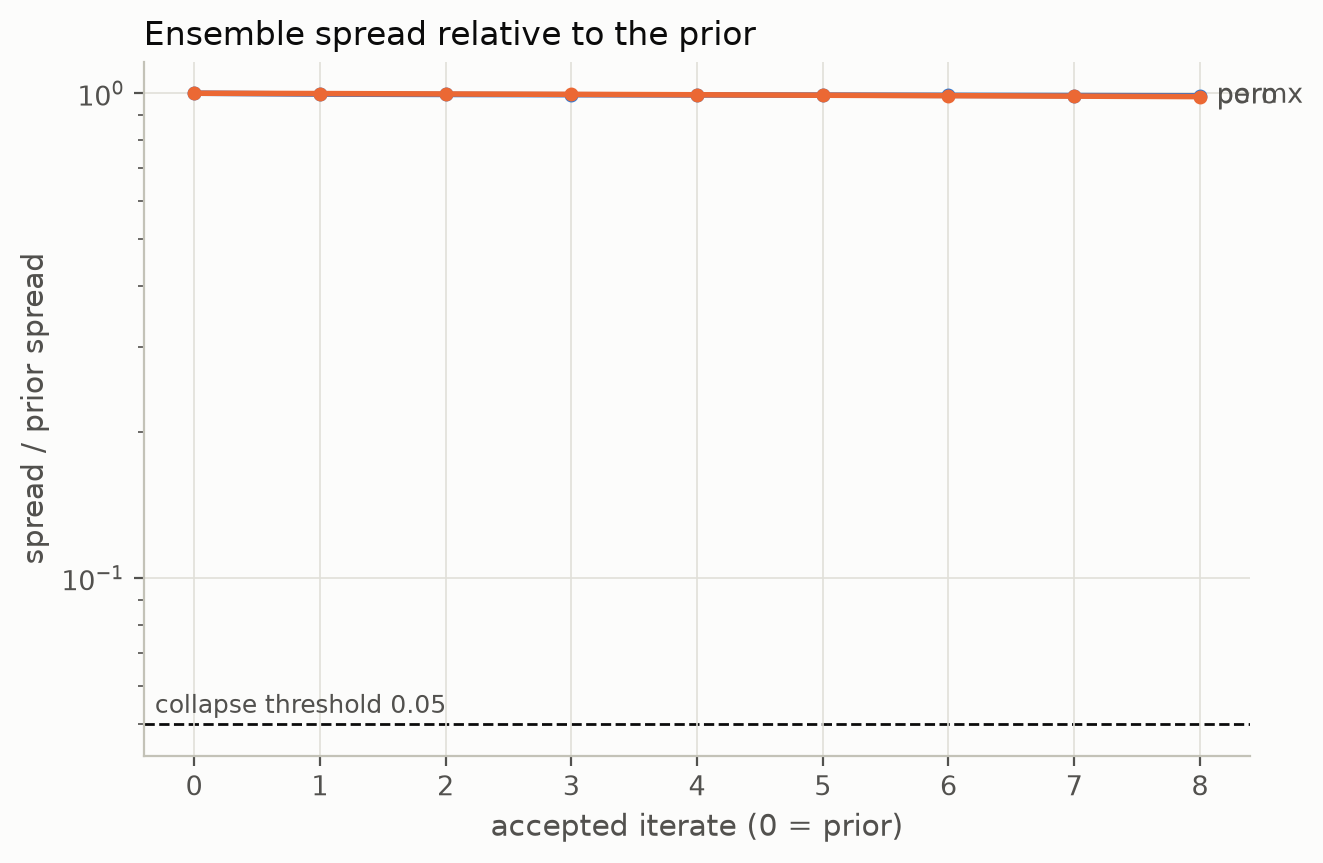

GIES, no localization


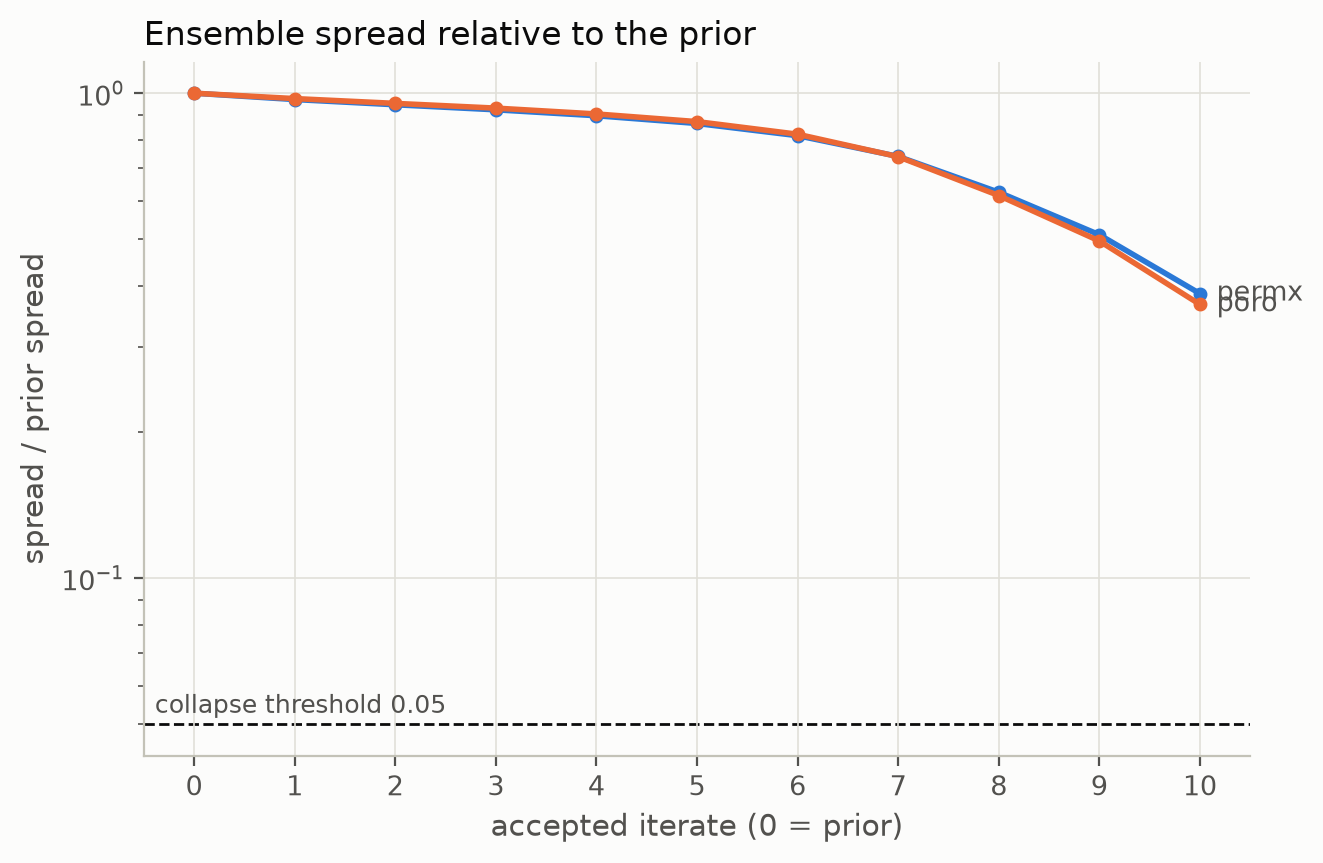

In [9]:
for name in ("gies", "gies_noloc"):
    health = runs[name] / "report" / "health"
    print(demo.EXPERIMENTS[name][0])
    display(Image(filename=health / "spread.png", width=560))